# Logic-LM Inspired Neuro-Symbolic Syllogism Graph Pipeline
This notebook replaces raw text inference loops with a formal **Neuro-Symbolic architecture** patterned after **Logic-LM** and similar frameworks.

### Pipeline Steps:
1. **Graph Ingestion:** Converts Abstract Syntax Trees (ASTs) from your FOLIO split into a unified graph using your custom `networkx` extraction logic.
2. **Neuro-Translator (SLM < 7B):** Leverages **Qwen2.5-7B-Instruct** to ingest the serialized graph tokens, generate a chain-of-thought (CoT) tracking trace, and output a valid Python solver snippet.
3. **Symbolic Verification Engine:** Executes the generated script within an isolated runtime environment to return a definitive boolean result (`True`/`False`), minimizing language hallucinations.

In [1]:
'''
task: FOL classification based on graph data from AST
model: graphormer
dataset: P-FOLIO
evaluation: supervised fine-tuning
'''
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Cell 1: Install prerequisites
!pip install networkx pandas transformers torch scikit-learn accelerate

In [3]:
# Cell 2: System Framework Imports
import json
import re
import os
import sys
import pandas as pd
import networkx as nx
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import classification_report, accuracy_score
import matplotlib.pyplot as plt

In [4]:
# Cell 3: Graph Construction Utilities from AST (Your Custom Logic Layer)
def extract_text(node):
    pieces = []
    if "text" in node:
        pieces.append(node["text"])
    if "children" in node:
        for child in node["children"]:
            pieces.extend(extract_text(child))
    return "".join(pieces)

def clean_syntax(text):
    return (text.strip()
            .replace("forall", "∀ ")
            .replace("implies", " → ")
            .replace("and", " ∧ ")
            .replace("not", " ¬ ")
            .replace("()", ""))

def ast_to_syllogism_graph(ast_dict):
    G = nx.DiGraph()
    root_node = "Syllogism"
    G.add_node(root_node, label="Syllogism", node_type="root")

    def find_statements(node):
        stats = []
        if not isinstance(node, dict):
            return stats
        if node.get("type") == "stat":
            stats.append(node)
        for child in node.get("children", []):
            stats.extend(find_statements(child))
        return stats

    statements = find_statements(ast_dict)
    if not statements:
        return G

    premises = statements[:-1]
    conclusion = statements[-1]

    def extract_sub_terms_from_node(node):
        if not isinstance(node, dict):
            return []
        sub_terms = []
        current_letters = []
        for child in node.get("children", []):
            child_type = child.get("type")
            if child_type == "COMMA":
                if current_letters:
                    sub_terms.append("".join(current_letters))
                    current_letters = []
            elif child_type == "LETTER" and "text" in child:
                current_letters.append(child["text"])
            else:
                nested = extract_sub_terms_from_node(child)
                if nested:
                    sub_terms.extend(nested)
        if current_letters:
            sub_terms.append("".join(current_letters))
        if not sub_terms and "text" in node:
            sub_terms.append(node["text"])
        return sub_terms

    def get_node_text(node):
        if not isinstance(node, dict): return ""
        if "text" in node: return node["text"]
        for child in node.get("children", []):
            res = get_node_text(child)
            if res: return res
        return ""

    def collect_keywords(node, keywords):
        if not isinstance(node, dict): return
        if node.get("type") == "keyword":
            kw_text = get_node_text(node)
            if kw_text and kw_text not in keywords:
                keywords.append(kw_text)
        for child in node.get("children", []):
            collect_keywords(child, keywords)

    def find_atomic_propositions(node):
        aps = []
        if not isinstance(node, dict): return aps
        if node.get("type") == "atomicproposition":
            aps.append(node)
        for child in node.get("children", []):
            aps.extend(find_atomic_propositions(child))
        return aps

    def add_merged_node(label, node_type):
        if not G.has_node(label):
            G.add_node(label, label=label, node_type=node_type)
        else:
            existing_type = G.nodes[label].get("node_type", "")
            if node_type not in existing_type:
                G.nodes[label]["node_type"] = f"{existing_type},{node_type}"
        return label

    def process_statement(stat_node, parent_graph_node):
        quantifier_label = None
        symbol_label = None

        def find_quantifier_symbol(node):
            nonlocal quantifier_label, symbol_label
            if not isinstance(node, dict): return
            ntype = node.get("type")
            if ntype == "quantifier":
                q_text = get_node_text(node)
                if q_text:
                    quantifier_label = add_merged_node(q_text, "quantifier")
                    G.add_edge(parent_graph_node, quantifier_label)
            elif ntype == "symbol" and quantifier_label:
                s_text = get_node_text(node)
                if s_text:
                    symbol_label = add_merged_node(s_text, "symbol")
                    G.add_edge(quantifier_label, symbol_label)
            for child in node.get("children", []):
                find_quantifier_symbol(child)

        find_quantifier_symbol(stat_node)
        aps = find_atomic_propositions(stat_node)
        statement_terms = set()

        for ap in aps:
            term_children = [c for c in ap.get("children", []) if c.get("type") == "term"]
            ap_terms = []
            for tc in term_children:
                sub = extract_sub_terms_from_node(tc)
                ap_terms.extend(sub)

            if ap_terms:
                predicate_text = ap_terms[0]
                pred_label = add_merged_node(predicate_text, "term")
                G.add_edge(parent_graph_node, pred_label)
                statement_terms.add(predicate_text)

                for arg_text in ap_terms[1:]:
                    arg_label = add_merged_node(arg_text, "term")
                    G.add_edge(parent_graph_node, arg_label)
                    statement_terms.add(arg_text)
                    G.add_edge(pred_label, arg_label)

        def find_all_terms(node):
            if not isinstance(node, dict): return
            if node.get("type") == "term":
                for t in extract_sub_terms_from_node(node):
                    if t not in statement_terms:
                        t_label = add_merged_node(t, "term")
                        G.add_edge(parent_graph_node, t_label)
                        statement_terms.add(t)
            for child in node.get("children", []):
                find_all_terms(child)

        find_all_terms(stat_node)
        keywords = []
        collect_keywords(stat_node, keywords)
        for kw in keywords:
            kw_label = add_merged_node(kw, "keyword")
            G.add_edge(parent_graph_node, kw_label)
            for t in statement_terms:
                G.add_edge(kw_label, t)

    for idx, premise in enumerate(premises):
        premise_name = f"Premise_{idx + 1}"
        add_merged_node(premise_name, "premise")
        G.add_edge(root_node, premise_name)
        process_statement(premise, premise_name)

    conclusion_name = "Conclusion"
    add_merged_node(conclusion_name, "conclusion")
    G.add_edge(root_node, conclusion_name)
    process_statement(conclusion, conclusion_name)

    return G

In [5]:
# Cell 4: Topographic Serialization
def serialize_graph_to_text(G: nx.DiGraph) -> str:
    nodes_list = []
    for node, data in G.nodes(data=True):
        ntype = data.get("node_type", "unknown")
        nodes_list.append(f"  - Node_ID: {node} | Type: {ntype}")

    edges_list = []
    for u, v in G.edges():
        edges_list.append(f"  - {u} -> {v}")

    return (
        f"### FIRST-ORDER LOGIC SYLLOGISM GRAPH REPRESENTATION\n\n"
        f"GRAPH NODES:\n{chr(10).join(nodes_list)}\n\n"
        f"TOPOLOGICAL DIRECTED EDGES:\n{chr(10).join(edges_list)}"
    )

In [6]:
# Cell 5: Symbolic Runtime Program Executor
def execute_symbolic_program(code_str):
    """Runs the code generated by the neuro model in an isolated environment block to extract values safely."""
    code_str = re.sub(r"```(?:python)?", "", code_str, flags=re.IGNORECASE).strip()
    local_env = {}
    old_stdout = sys.stdout
    sys.stdout = open(os.devnull, 'w')
    try:
        exec(code_str, {}, local_env)
        verdict = local_env.get("result", None)
        sys.stdout = old_stdout
        return verdict, "Success"
    except Exception as e:
        sys.stdout = old_stdout
        return None, f"Runtime Crash: {str(e)}"

In [18]:
model_id = "Qwen/Qwen2.5-7B-Instruct"
print(f"Initializing base language engine model: {model_id}...")
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

def run_neuro_symbolic_generator(serialized_graph):
    system_instruction = (
        "You are an expert Neuro-Symbolic reasoner matching the Logic-LM architecture framework.\n"
        "Your task is to review the First-Order Logic syllogism graph, "
        "generate a chain-of-thought (CoT) tracking trace explaining the argument layout, and translate it "
        "into a runnable Python symbolic solver snippet.\n\n"
        "CRITICAL PROGRAMMING INSTRUCTIONS:\n"
        "1. Do NOT define helper functions (like `def premise_1():`). Instead, write explicit, sequential SymPy statements.\n"
        "2. Use SymPy to declare individual propositions as boolean symbols (e.g., `A, B, C = symbols('A B C')`).\n"
        "3. Represent premises directly as SymPy logical expressions using `And`, `Or`, `Not`, `Implies`.\n"
        "4. Conclude by checking the satisfiability or logical consequence of the conclusion given the premises, "
        "and assign the evaluation outcome to the global boolean variable `result` (True, False, or 'Uncertain').\n"
        "5. Wrap the code in a single ```python block at the absolute end of your response."
    )
    user_query = f"{serialized_graph}\n\nPerform path checking reasoning. Then write the execution script."
    messages = [
        {"role": "system", "content": system_instruction},
        {"role": "user", "content": user_query}
    ]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(**inputs, max_new_tokens=1536, temperature=0.1, do_sample=False)
    # Extract only the newly generated tokens
    generated_tokens = outputs[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(generated_tokens, skip_special_tokens=True)

Initializing base language engine model: Qwen/Qwen2.5-7B-Instruct...


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

In [19]:
# Cell 7: End-to-End Evaluation Loop Framework
def process_row_to_graph(row):
    try:
        # Robust JSON deserialization
        p_str = row["Premises - CLIF"].strip()
        c_str = row["Conclusions - CLIF"].strip()

        # Standardize single quotes to double quotes for standard JSON compatibility
        if p_str.startswith("'") and p_str.endswith("'"):
            p_str = p_str[1:-1]
        if c_str.startswith("'") and c_str.endswith("'"):
            c_str = c_str[1:-1]

        # Replace Python single quotes with valid JSON double quotes
        p_str = p_str.replace("'", '"')
        c_str = c_str.replace("'", '"')

        p_dict = json.loads(p_str)
        c_dict = json.loads(c_str)

        # Ensure we establish structural roots for the ast_to_syllogism_graph parser
        if isinstance(p_dict, list):
            p_dict = {"type": "root", "children": p_dict}
        elif "children" not in p_dict:
            p_dict = {"type": "root", "children": [p_dict]}

        if isinstance(c_dict, list):
            c_dict = {"type": "root", "children": c_dict}
        elif "children" not in c_dict:
            c_dict = {"type": "root", "children": [c_dict]}

        # Combine premises and conclusions into a single child sequence
        combined_children = list(p_dict.get("children", [])) + list(c_dict.get("children", []))
        return ast_to_syllogism_graph({"type": "root", "children": combined_children})
    except Exception as e:
        print(f"Parsing exception: {e}")
        return None

csv_path = "/content/drive/MyDrive/Colab Notebooks/folio/data/folio_ast_test.csv"
if os.path.exists(csv_path):
    # Read the full dataset to evaluate all rows
    eval_df = pd.read_csv(csv_path).copy()
    cot_traces, final_verdicts = [], []
    total_rows = len(eval_df)
    print(f"Found {total_rows} rows to process in the dataset. Beginning pipeline...")

    for idx, row in eval_df.iterrows():
        if (idx + 1) % 10 == 0 or (idx + 1) == total_rows:
            print(f"Processing row {idx + 1}/{total_rows}...")

        g = process_row_to_graph(row)
        if g is not None and len(g.nodes) > 1:
            serialized_text = serialize_graph_to_text(g)
            neuro_output = run_neuro_symbolic_generator(serialized_text)
            code_blocks = re.findall(r"```python(.*?)```", neuro_output, re.DOTALL)
            script = code_blocks[0].strip() if code_blocks else neuro_output
            verdict, status = execute_symbolic_program(script)

            # Map symbolic outputs to FOLIO's official string labels: True, False, or Uncertain
            if verdict is True:
                mapped_verdict = "True"
            elif verdict is False:
                mapped_verdict = "False"
            elif str(verdict).lower() in ["uncertain", "unknown"]:
                mapped_verdict = "Uncertain"
            else:
                mapped_verdict = "Uncertain"  # Default fallback for logic solvers

            cot_traces.append(neuro_output)
            final_verdicts.append(mapped_verdict)
        else:
            cot_traces.append("Graph build failure or empty graph")
            final_verdicts.append("Uncertain")

    eval_df["Neuro_CoT_Trace"] = cot_traces
    eval_df["Final_Verdict"] = final_verdicts
    print("\nPipeline execution complete! Overall Accuracy Report:")
    if "label" in eval_df.columns:
        print(classification_report(eval_df["label"], eval_df["Final_Verdict"]))
    display(eval_df[["label", "Final_Verdict"]].head(20))
else:
    print(f"Target file path missing: '{csv_path}'")

Found 201 rows to process in the dataset. Beginning pipeline...


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
    ~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_7475/4219757303.py", line 54, in <cell line: 0>
    neuro_output = run_neuro_symbolic_generator(serialized_text)
  File "/tmp/ipykernel_7475/2753546709.py", line 32, in run_neuro_symbolic_generator
    outputs = model.generate(**inputs, max_new_tokens=1536, temperature=0.1, do_sample=False)
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 124, in decorate_context
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 2989, in generate
    result = decoding_method(
        self,
    ...<5 lines>...
        **model_kwargs,
    )
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 3217, in

TypeError: object of type 'NoneType' has no len()

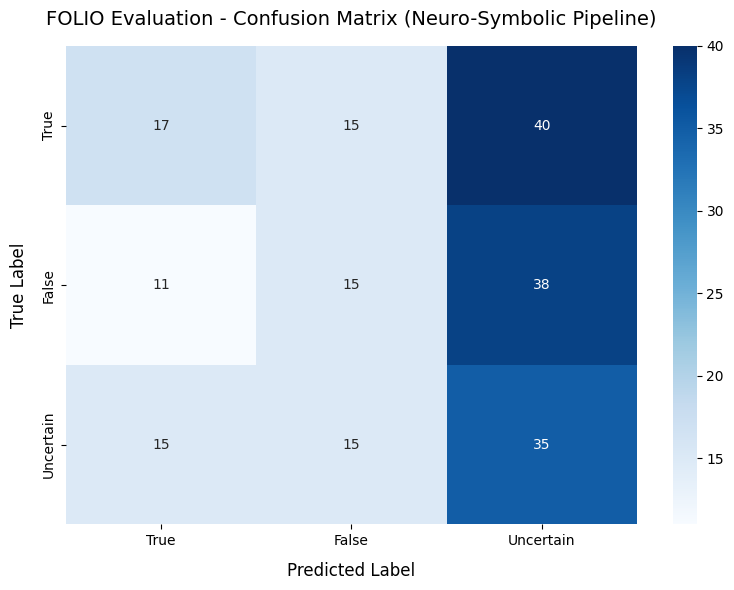

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Define the labels in standard logical/alphabetical order for clean presentation
labels = ["True", "False", "Uncertain"]

# Compute the confusion matrix using actual vs predicted values
cm = confusion_matrix(eval_df["label"], eval_df["Final_Verdict"], labels=labels)

# Draw the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True
)

plt.title("FOLIO Evaluation - Confusion Matrix (Neuro-Symbolic Pipeline)", fontsize=14, pad=15)
plt.xlabel("Predicted Label", fontsize=12, labelpad=10)
plt.ylabel("True Label", fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

In [17]:
# Cell to investigate 'True' actual labels that were predicted as 'Uncertain'
# We filter the evaluation DataFrame to inspect these mismatch cases
target_mismatches = eval_df[(eval_df["label"] == "True") & (eval_df["Final_Verdict"] == "Uncertain")]

print(f"Total mismatch cases (True -> Uncertain): {len(target_mismatches)}\n")

# Display details for the first 3 cases for deep parsing
for idx, (_, row) in enumerate(target_mismatches.head(3).iterrows()):
    print(f"=== MISMATCH EXAMPLE {idx + 1} (Story ID: {row.get('story_id', 'N/A')}) ===")
    print(f"Premises Text: {row.get('premises', 'N/A')[:200]}...")
    print(f"Conclusion Text: {row.get('conclusion', 'N/A')}")

    # Extract and display the python code block generated
    trace = row.get("Neuro_CoT_Trace", "")
    code_blocks = re.findall(r"```python(.*?)```", trace, re.DOTALL)
    generated_code = code_blocks[0].strip() if code_blocks else "No python code block found"

    # Re-run the isolated solver to retrieve actual error messages
    verdict, status = execute_symbolic_program(generated_code)

    print(f"\nGenerated Code Snippet:\n{generated_code[:400]}\n...")
    print(f"Symbolic Execution Status: {status}")
    print(f"Symbolic Execution Result: {verdict}")
    print("="*60 + "\n")

Total mismatch cases (True -> Uncertain): 40

=== MISMATCH EXAMPLE 1 (Story ID: 469) ===
Premises Text: All members of the university faculty are professors.
All principal investigators are members of the university faculty.
No professor is also an undergraduate student.
Anyone pursuing a bachelor's ...
Conclusion Text: Leon is neither an undergraduate student nor a principal investigator.

Generated Code Snippet:
No python code block found
...
Symbolic Execution Status: Runtime Crash: invalid syntax (<string>, line 1)
Symbolic Execution Result: None

=== MISMATCH EXAMPLE 2 (Story ID: 84) ===
Premises Text: Luzon is an island in the Philippines.
In December 1999, an earthquake struck Luzon.
People died in the December 1999 earthquake in Luzon....
Conclusion Text: In 1999, there was at least one earthquake in the Philippines.

Generated Code Snippet:
# Define the premises as logical statements
def premise_1():
    # i is in sl, l is in uzon, in is in luzon, in is in philippines, in is i